In [ ]:
import zipfile
import os
import pandas as pd

# Path of the uploaded ZIP file
zip_path = "/content/crop_recommendation_dataset.zip"

# Extract the ZIP
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/crop_dataset")

# Show extracted files
print("Extracted files:")
for root, dirs, files in os.walk("/content/crop_dataset"):
    for file in files:
        print(os.path.join(root, file))

Extracted files:
/content/crop_dataset/Crop_recommendation.csv


In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv("/content/crop_dataset/Crop_recommendation.csv")

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (2200, 8)

Column Names:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

First 5 Rows:


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [ ]:
# Check number of unique crops
print("Number of crop classes:", df["label"].nunique())

print("\nCrop classes:")
print(sorted(df["label"].unique()))

print("\nSamples per crop:")
print(df["label"].value_counts().sort_index())

print("\nTotal duplicate rows:", df.duplicated().sum())

Number of crop classes: 22

Crop classes:
['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']

Samples per crop:
label
apple          100
banana         100
blackgram      100
chickpea       100
coconut        100
coffee         100
cotton         100
grapes         100
jute           100
kidneybeans    100
lentil         100
maize          100
mango          100
mothbeans      100
mungbean       100
muskmelon      100
orange         100
papaya         100
pigeonpeas     100
pomegranate    100
rice           100
watermelon     100
Name: count, dtype: int64

Total duplicate rows: 0


In [ ]:
# Separate input features (X) and target (y)

X = df.drop("label", axis=1)
y = df["label"]

print("Input features:")
print(X.columns.tolist())

print("\nNumber of input features:", X.shape[1])
print("Number of samples:", X.shape[0])

print("\nTarget classes:", y.nunique())
print(sorted(y.unique()))

Input features:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

Number of input features: 7
Number of samples: 2200

Target classes: 22
['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']


In [ ]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training samples: 1760
Testing samples: 440

Training class distribution:
label
apple          80
banana         80
blackgram      80
chickpea       80
coconut        80
coffee         80
cotton         80
grapes         80
jute           80
kidneybeans    80
lentil         80
maize          80
mango          80
mothbeans      80
mungbean       80
muskmelon      80
orange         80
papaya         80
pigeonpeas     80
pomegranate    80
rice           80
watermelon     80
Name: count, dtype: int64

Testing class distribution:
label
apple          20
banana         20
blackgram      20
chickpea       20
coconut        20
coffee         20
cotton         20
grapes         20
jute           20
kidneybeans    20
lentil         20
maize          20
mango          20
mothbeans      20
mungbean       20
muskmelon      20
orange         20
papaya         20
pigeonpeas     20
pomegranate    20
rice           20
watermelon     20
Name: count, dtype: int64


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create Random Forest model
random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

# Train the model
random_forest.fit(X_train, y_train)

# Make predictions
y_pred_rf = random_forest.predict(X_test)

# Calculate accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.9954545454545455

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange  

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create Decision Tree model
decision_tree = DecisionTreeClassifier(
    random_state=42
)

# Train the model
decision_tree.fit(X_train, y_train)

# Make predictions
y_pred_dt = decision_tree.predict(X_test)

# Calculate accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.9795454545454545

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.80      0.89        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      0.95      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.86      0.90      0.88        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.86      0.95      0.90        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange  

In [ ]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

# Encode crop labels for XGBoost
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Create XGBoost model
xgboost_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="mlogloss"
)

# Train the model
xgboost_model.fit(X_train, y_train_encoded)

# Make predictions
y_pred_xgb_encoded = xgboost_model.predict(X_test)

# Calculate accuracy
accuracy_xgb = accuracy_score(y_test_encoded, y_pred_xgb_encoded)

print("XGBoost Accuracy:", accuracy_xgb)

print("\nClassification Report:")
print(
    classification_report(
        y_test_encoded,
        y_pred_xgb_encoded,
        target_names=label_encoder.classes_
    )
)

XGBoost Accuracy: 0.9863636363636363

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       0.95      1.00      0.98        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.91      1.00      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.85      0.92        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.95      1.00      0.98        20
    mungbean       0.91      1.00      0.95        20
   muskmelon       1.00      1.00      1.00        20
      orange       1

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create Gradient Boosting model
gradient_boosting = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train the model
gradient_boosting.fit(X_train, y_train)

# Make predictions
y_pred_gb = gradient_boosting.predict(X_test)

# Calculate accuracy
accuracy_gb = accuracy_score(y_test, y_pred_gb)

print("Gradient Boosting Accuracy:", accuracy_gb)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

Gradient Boosting Accuracy: 0.9886363636363636

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.91      1.00      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.95      0.97        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.91      1.00      0.95        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      oran

In [ ]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Decision Tree",
        "XGBoost",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_rf,
        accuracy_dt,
        accuracy_xgb,
        accuracy_gb
    ]
})

model_comparison["Accuracy (%)"] = (
    model_comparison["Accuracy"] * 100
).round(2)

model_comparison = model_comparison.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

display(model_comparison)

,Model,Accuracy,Accuracy (%)
0,Random Forest,0.995455,99.55
1,Gradient Boosting,0.988636,98.86
2,XGBoost,0.986364,98.64
3,Decision Tree,0.979545,97.95


In [ ]:
# Comprehensive dataset quality validation

print("========== DATASET QUALITY VALIDATION ==========\n")

# 1. Missing values
print("1. Missing values:")
print(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())

# 2. Duplicate rows
print("\n2. Duplicate rows:")
print("Total duplicates:", df.duplicated().sum())

# 3. Data types
print("\n3. Data types:")
print(df.dtypes)

# 4. Unique values
print("\n4. Unique values:")
print(df.nunique())

# 5. Basic statistical summary
print("\n5. Statistical summary:")
display(df.describe())

# 6. Target information
print("\n6. Target information:")
print("Number of crop classes:", df["label"].nunique())
print("Total samples:", len(df))

print("\nSamples per crop:")
print(df["label"].value_counts().sort_index())

========== DATASET QUALITY VALIDATION ==========

1. Missing values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64
Total missing values: 0

2. Duplicate rows:
Total duplicates: 0

3. Data types:
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object

4. Unique values:
N               137
P               117
K                73
temperature    2200
humidity       2200
ph             2200
rainfall       2200
label            22
dtype: int64

5. Statistical summary:


,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117



6. Target information:
Number of crop classes: 22
Total samples: 2200

Samples per crop:
label
apple          100
banana         100
blackgram      100
chickpea       100
coconut        100
coffee         100
cotton         100
grapes         100
jute           100
kidneybeans    100
lentil         100
maize          100
mango          100
mothbeans      100
mungbean       100
muskmelon      100
orange         100
papaya         100
pigeonpeas     100
pomegranate    100
rice           100
watermelon     100
Name: count, dtype: int64


In [ ]:
# Outlier Analysis using IQR Method

print("========== OUTLIER ANALYSIS ==========\n")

numeric_features = [
    "N",
    "P",
    "K",
    "temperature",
    "humidity",
    "ph",
    "rainfall"
]

outlier_summary = []

for feature in numeric_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": feature,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier %": (len(outliers) / len(df)) * 100
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df)

========== OUTLIER ANALYSIS ==========



,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,N,21.000000,84.250000,63.250000,-73.875000,179.125000,0,0.000000
1,P,28.000000,68.000000,40.000000,-32.000000,128.000000,138,6.272727
2,K,20.000000,49.000000,29.000000,-23.500000,92.500000,200,9.090909
3,temperature,22.769375,28.561654,5.792279,14.080956,37.250073,86,3.909091
4,humidity,60.261953,89.948771,29.686818,15.731726,134.478998,30,1.363636
5,ph,5.971693,6.923643,0.951950,4.543768,8.351567,57,2.590909
6,rainfall,64.551686,124.267508,59.715822,-25.022047,213.841241,100,4.545455


========== FEATURE DISTRIBUTION ANALYSIS ==========



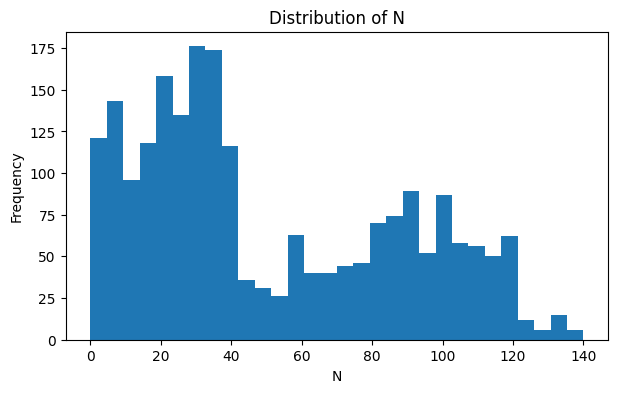

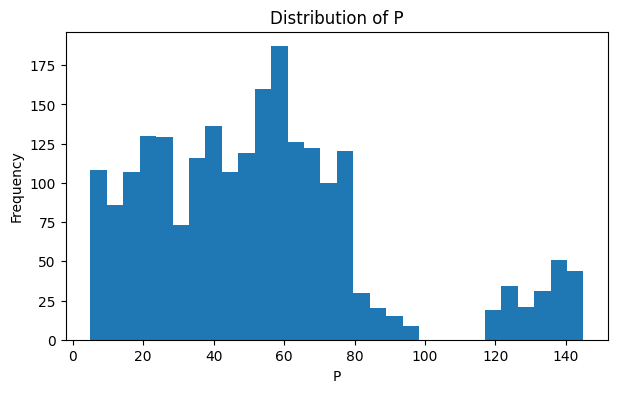

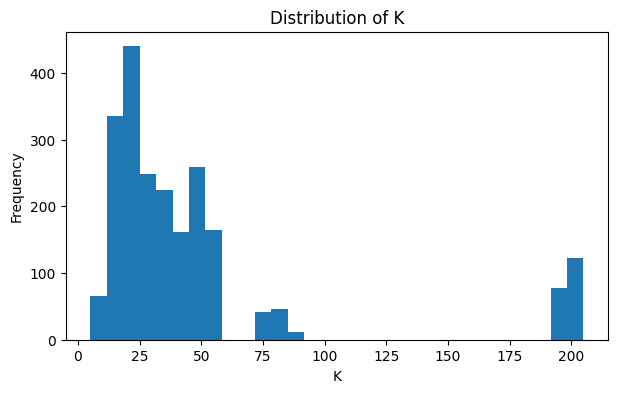

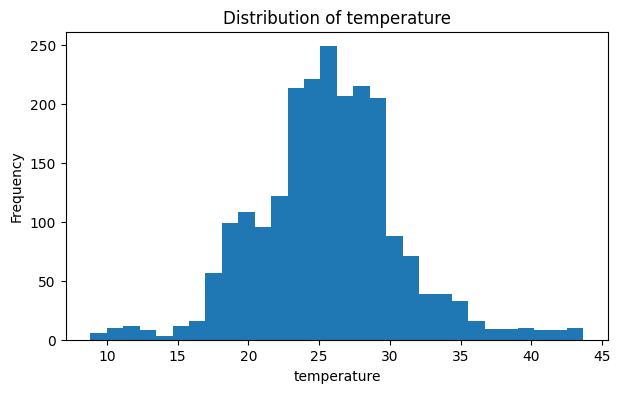

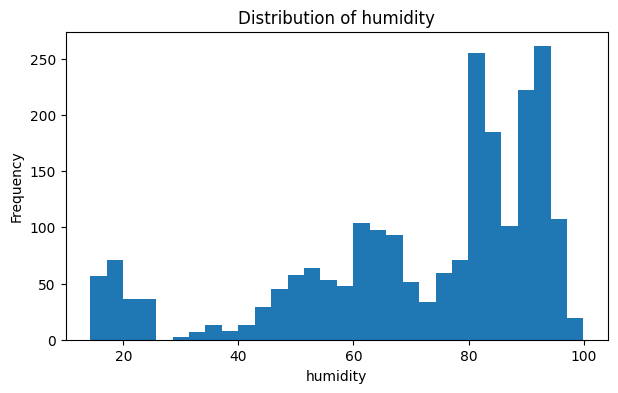

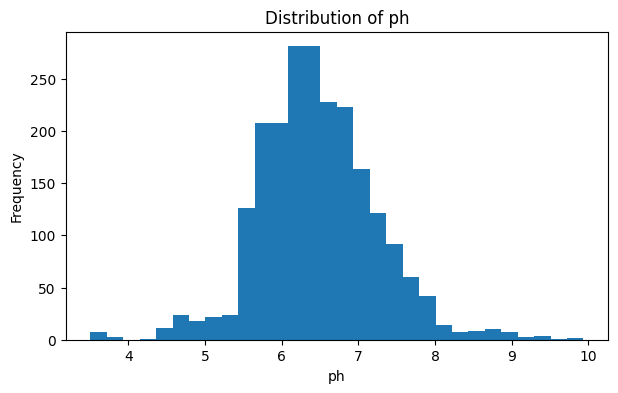

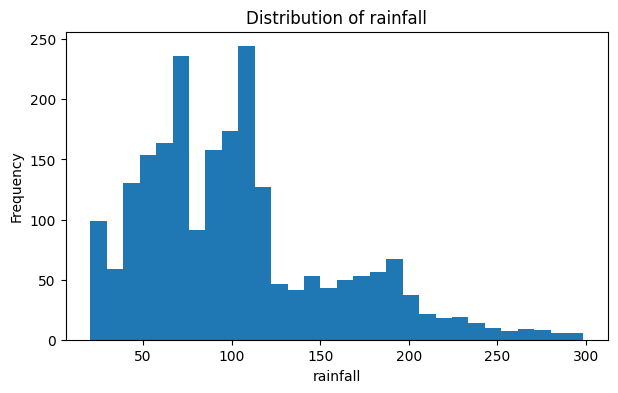

In [ ]:
# Feature Distribution Analysis

import matplotlib.pyplot as plt

print("========== FEATURE DISTRIBUTION ANALYSIS ==========\n")

numeric_features = [
    "N",
    "P",
    "K",
    "temperature",
    "humidity",
    "ph",
    "rainfall"
]

for feature in numeric_features:
    plt.figure(figsize=(7, 4))
    plt.hist(df[feature], bins=30)
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.show()

In [ ]:
# Feature Distribution Analysis - Table Format

print("========== FEATURE DISTRIBUTION ANALYSIS ==========\n")

numeric_features = [
    "N",
    "P",
    "K",
    "temperature",
    "humidity",
    "ph",
    "rainfall"
]

distribution_summary = []

for feature in numeric_features:
    distribution_summary.append({
        "Feature": feature,
        "Mean": df[feature].mean(),
        "Median": df[feature].median(),
        "Std Dev": df[feature].std(),
        "Minimum": df[feature].min(),
        "Maximum": df[feature].max(),
        "Skewness": df[feature].skew()
    })

distribution_df = pd.DataFrame(distribution_summary)

display(distribution_df.round(3))

========== FEATURE DISTRIBUTION ANALYSIS ==========



,Feature,Mean,Median,Std Dev,Minimum,Maximum,Skewness
0,N,50.552,37.000,36.917,0.000,140.000,0.510
1,P,53.363,51.000,32.986,5.000,145.000,1.011
2,K,48.149,32.000,50.648,5.000,205.000,2.375
3,temperature,25.616,25.599,5.064,8.826,43.675,0.185
4,humidity,71.482,80.473,22.264,14.258,99.982,-1.092
5,ph,6.469,6.425,0.774,3.505,9.935,0.284
6,rainfall,103.464,94.868,54.958,20.211,298.560,0.966


In [ ]:
# Feature Correlation Analysis

print("========== FEATURE CORRELATION ANALYSIS ==========\n")

correlation_matrix = df[numeric_features].corr()

display(correlation_matrix.round(3))

========== FEATURE CORRELATION ANALYSIS ==========



,N,P,K,temperature,humidity,ph,rainfall
N,1.000,-0.231,-0.141,0.027,0.191,0.097,0.059
P,-0.231,1.000,0.736,-0.128,-0.119,-0.138,-0.064
K,-0.141,0.736,1.000,-0.160,0.191,-0.170,-0.053
temperature,0.027,-0.128,-0.160,1.000,0.205,-0.018,-0.030
humidity,0.191,-0.119,0.191,0.205,1.000,-0.008,0.094
ph,0.097,-0.138,-0.170,-0.018,-0.008,1.000,-0.109
rainfall,0.059,-0.064,-0.053,-0.030,0.094,-0.109,1.000


In [ ]:
# Random Forest Feature Importance Analysis

print("========== RANDOM FOREST FEATURE IMPORTANCE ==========\n")

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

feature_importance["Importance (%)"] = (
    feature_importance["Importance"] * 100
)

display(feature_importance.round(4))

========== RANDOM FOREST FEATURE IMPORTANCE ==========



NameError: name 'rf_model' is not defined

In [ ]:
# Check the variables currently available for trained models

print("Checking available model variables...\n")

for name, value in globals().items():
    if "model" in name.lower() or "forest" in name.lower():
        print(name, "->", type(value))

Checking available model variables...



RuntimeError: dictionary changed size during iteration

In [ ]:
# Check available model variables

print("Checking available model variables...\n")

for name, value in list(globals().items()):
    if "model" in name.lower() or "forest" in name.lower():
        print(name, "->", type(value))

Checking available model variables...

RandomForestClassifier -> <class 'abc.ABCMeta'>
random_forest -> <class 'sklearn.ensemble._forest.RandomForestClassifier'>
xgboost_model -> <class 'xgboost.sklearn.XGBClassifier'>
model_comparison -> <class 'pandas.core.frame.DataFrame'>


In [ ]:
# Random Forest Feature Importance Analysis

print("========== RANDOM FOREST FEATURE IMPORTANCE ==========\n")

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

feature_importance["Importance (%)"] = (
    feature_importance["Importance"] * 100
)

display(feature_importance.round(4))

========== RANDOM FOREST FEATURE IMPORTANCE ==========



,Feature,Importance,Importance (%)
0,rainfall,0.2196,21.9641
1,humidity,0.2171,21.7058
2,K,0.1808,18.0813
3,P,0.1513,15.1342
4,N,0.1034,10.3356
5,temperature,0.0755,7.5485
6,ph,0.0523,5.2305


In [ ]:
# Feature Range Analysis by Crop

print("========== FEATURE RANGE BY CROP ==========\n")

crop_feature_summary = df.groupby("label")[numeric_features].agg(
    ["min", "max", "mean"]
)

display(crop_feature_summary.round(2))

========== FEATURE RANGE BY CROP ==========



N                 P                 K              temperature  \
             min  max    mean  min  max    mean  min  max    mean         min   
label                                                                           
apple          0   40   20.80  120  145  134.22  195  205  199.89       21.04   
banana        80  120  100.23   70   95   82.01   45   55   50.05       25.01   
blackgram     20   60   40.02   55   80   67.47   15   25   19.24       25.10   
chickpea      20   60   40.09   55   80   67.79   75   85   79.92       17.02   
coconut        0   40   21.98    5   30   16.93   25   35   30.59       25.01   
coffee        80  120  101.20   15   40   28.74   25   35   29.94       23.06   
cotton       100  140  117.77   35   60   46.24   15   25   19.56       22.00   
grapes         0   40   23.18  120  145  132.53  195  205  200.11        8.83   
jute          60  100   78.40   35   60   46.86   35   45   39.99       23.09   
kidneybeans    0   40   20.75   55   80   67.54   15   25   20.05       15.33   
lentil         0   40   18.77   55   80   68.36   15   25   19.41       18.06   
maize         60  100   77.76   35   60   48.44   15   25   19.79       18.04   
mango          0   40   20.07   15   40   27.18   25   35   29.92       27.00   
mothbeans      0   40   21.44   35   60   48.01   15   25   20.23       24.02   
mungbean       0   40   20.99   35   60   47.28   15   25   19.87       27.01   
muskmelon     80  120  100.32    5   30   17.72   45   55   50.08       27.02   
orange         0   40   19.58    5   30   16.55    5   15   10.01       10.01   
papaya        31   70   49.88   46   70   59.05   45   55   50.04       23.01   
pigeonpeas     0   40   20.73   55   80   67.73   15   25   20.29       18.32   
pomegranate    0   40   18.87    5   30   18.75   35   45   40.21       18.07   
rice          60   99   79.89   35   60   47.58   35   45   39.87       20.05   
watermelon    80  120   99.42    5   30   17.00   45   55   50.22       24.04   

             ...        humidity                  ph             rainfall  \
             ...   mean      min    max   mean   min   max  mean      min   
label        ...                                                            
apple        ...  22.63    90.03  94.92  92.33  5.51  6.50  5.93   100.12   
banana       ...  27.38    75.03  84.98  80.36  5.51  6.49  5.98    90.11   
blackgram    ...  29.97    60.07  69.96  65.12  6.50  7.78  7.13    60.42   
chickpea     ...  18.87    14.26  19.97  16.86  5.99  8.87  7.34    65.11   
coconut      ...  27.41    90.02  99.98  94.84  5.50  6.47  5.98   131.09   
coffee       ...  25.54    50.05  69.95  58.87  6.02  7.49  6.79   115.16   
cotton       ...  23.99    75.01  84.88  79.84  5.80  7.99  6.91    60.65   
grapes       ...  23.85    80.02  83.98  81.88  5.51  6.50  6.03    65.01   
jute         ...  24.96    70.88  89.89  79.64  6.00  7.49  6.73   150.24   
kidneybeans  ...  20.12    18.09  24.97  21.61  5.50  6.00  5.75    60.28   
lentil       ...  24.51    60.09  69.92  64.80  5.92  7.84  6.93    35.03   
maize        ...  22.39    55.28  74.83  65.09  5.51  7.00  6.25    60.65   
mango        ...  31.21    45.02  54.96  50.16  4.51  6.97  5.77    89.29   
mothbeans    ...  28.19    40.01  64.96  53.16  3.50  9.94  6.83    30.92   
mungbean     ...  28.53    80.03  90.00  85.50  6.22  7.20  6.72    36.12   
muskmelon    ...  28.66    90.02  94.96  92.34  6.00  6.78  6.36    20.21   
orange       ...  22.77    90.01  94.96  92.17  6.01  8.00  7.02   100.17   
papaya       ...  33.72    90.04  94.94  92.40  6.50  6.99  6.74    40.35   
pigeonpeas   ...  27.74    30.40  69.69  48.06  4.55  7.45  5.79    90.05   
pomegranate  ...  21.84    85.13  95.00  90.13  5.56  7.20  6.43   102.52   
rice         ...  23.69    80.12  84.97  82.27  5.01  7.87  6.43   182.56   
watermelon   ...  25.59    80.03  89.98  85.16  6.00  6.96  6.50    40.13   

                             
                max    mean  
lab

In [ ]:
# 5-Fold Stratified Cross-Validation for Random Forest

from sklearn.model_selection import StratifiedKFold, cross_val_score

print("========== 5-FOLD CROSS-VALIDATION ==========\n")

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    random_forest,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Fold accuracies:")

for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: {score:.4f} ({score * 100:.2f}%)")

print("\nMean Cross-Validation Accuracy:")
print(f"{cv_scores.mean():.4f} ({cv_scores.mean() * 100:.2f}%)")

print("\nStandard Deviation:")
print(f"{cv_scores.std():.4f} ({cv_scores.std() * 100:.2f}%)")

========== 5-FOLD CROSS-VALIDATION ==========

Fold accuracies:
Fold 1: 0.9955 (99.55%)
Fold 2: 0.9932 (99.32%)
Fold 3: 1.0000 (100.00%)
Fold 4: 0.9977 (99.77%)
Fold 5: 0.9932 (99.32%)

Mean Cross-Validation Accuracy:
0.9959 (99.59%)

Standard Deviation:
0.0027 (0.27%)


In [ ]:
print("========== FINAL MODEL VALIDATION ==========\n")

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Predictions from the Random Forest on the untouched test set
y_test_pred = random_forest.predict(X_test)

# Test accuracy
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Random Forest Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

========== FINAL MODEL VALIDATION ==========

Random Forest Test Accuracy: 0.9955 (99.55%)

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1

In [ ]:
print("========== FINAL MODEL ==========\n")

final_model = random_forest

feature_order = [
    "N",
    "P",
    "K",
    "temperature",
    "humidity",
    "ph",
    "rainfall"
]

print("Final Model: Random Forest Classifier")
print(f"Number of Trees: {final_model.n_estimators}")
print(f"Number of Features: {final_model.n_features_in_}")
print(f"Number of Crop Classes: {len(final_model.classes_)}")

print("\nFeature Order:")
for i, feature in enumerate(feature_order, start=1):
    print(f"{i}. {feature}")

print("\nCrop Classes:")
print(list(final_model.classes_))

print("\nFinal Validation Results:")
print(f"Held-out Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"5-Fold CV Mean Accuracy: {cv_scores.mean() * 100:.2f}%")
print(f"5-Fold CV Std. Deviation: {cv_scores.std() * 100:.2f}%")

print("\n========== MODEL READY FOR SAVING ==========")

========== FINAL MODEL ==========

Final Model: Random Forest Classifier
Number of Trees: 200
Number of Features: 7
Number of Crop Classes: 22

Feature Order:
1. N
2. P
3. K
4. temperature
5. humidity
6. ph
7. rainfall

Crop Classes:
['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']

Final Validation Results:
Held-out Test Accuracy: 99.55%
5-Fold CV Mean Accuracy: 99.59%
5-Fold CV Std. Deviation: 0.27%

========== MODEL READY FOR SAVING ==========


In [ ]:
import joblib
import os

print("========== SAVING FINAL MODEL ==========\n")

# Create a folder for FarmSathi ML models
os.makedirs("farmsathi_models", exist_ok=True)

# Save the final Random Forest model
model_path = "farmsathi_models/farmsathi_crop_recommendation_rf.pkl"

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print(f"Model path: {model_path}")

# Verify that the file exists
if os.path.exists(model_path):
    file_size = os.path.getsize(model_path) / 1024

    print(f"File size: {file_size:.2f} KB")
    print("Status: READY FOR DEPLOYMENT")
else:
    print("ERROR: Model file was not created.")

========== SAVING FINAL MODEL ==========

Model saved successfully!
Model path: farmsathi_models/farmsathi_crop_recommendation_rf.pkl
File size: 7110.51 KB
Status: READY FOR DEPLOYMENT


In [ ]:
print("========== SAVED MODEL VERIFICATION ==========\n")

import joblib

# Load the saved model
loaded_model = joblib.load(model_path)

print("Saved model loaded successfully!")

# Verify model properties
print(f"Number of Trees: {loaded_model.n_estimators}")
print(f"Number of Features: {loaded_model.n_features_in_}")
print(f"Number of Crop Classes: {len(loaded_model.classes_)}")

# Compare predictions from original and loaded models
original_predictions = final_model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

predictions_match = (original_predictions == loaded_predictions).all()

print(f"\nOriginal and loaded predictions match: {predictions_match}")

if predictions_match:
    print("Verification successful!")
    print("The saved model is ready for FarmSathi integration.")
else:
    print("WARNING: Predictions do not match.")

========== SAVED MODEL VERIFICATION ==========

Saved model loaded successfully!
Number of Trees: 200
Number of Features: 7
Number of Crop Classes: 22

Original and loaded predictions match: True
Verification successful!
The saved model is ready for FarmSathi integration.


In [ ]:
print("========== NEW INPUT PREDICTION TEST ==========\n")

import pandas as pd

# Example agricultural conditions
new_input = pd.DataFrame([{
    "N": 90,
    "P": 42,
    "K": 43,
    "temperature": 25.0,
    "humidity": 80.0,
    "ph": 6.5,
    "rainfall": 200.0
}])

# Make prediction using the SAVED/LOADED model
prediction = loaded_model.predict(new_input)[0]

# Get prediction probabilities
probabilities = loaded_model.predict_proba(new_input)[0]

# Find the top 3 recommendations
top_3_indices = probabilities.argsort()[-3:][::-1]

print("Input Values:")
print(new_input.to_string(index=False))

print(f"\nRecommended Crop: {prediction}")

print("\nTop 3 Model Predictions:")
for rank, index in enumerate(top_3_indices, start=1):
    print(
        f"{rank}. {loaded_model.classes_[index]} "
        f"({probabilities[index] * 100:.2f}%)"
    )

========== NEW INPUT PREDICTION TEST ==========

Input Values:
 N  P  K  temperature  humidity  ph  rainfall
90 42 43         25.0      80.0 6.5     200.0

Recommended Crop: rice

Top 3 Model Predictions:
1. rice (52.00%)
2. jute (47.50%)
3. watermelon (0.50%)


In [ ]:
# ============================================
# FarmSathi - Crop Recommendation
# Accuracy Comparison of ML Algorithms
# ============================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier


# --------------------------------------------
# 1. Load Dataset
# --------------------------------------------

df = pd.read_csv('/content/Crop_recommendation.csv')

print("Dataset shape:", df.shape)
print(df.head())


# --------------------------------------------
# 2. Separate Features and Target
# --------------------------------------------

X = df.drop('label', axis=1)
y = df['label']


# --------------------------------------------
# 3. Encode Crop Labels
# --------------------------------------------

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)


# --------------------------------------------
# 4. Train-Test Split
# --------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


# --------------------------------------------
# 5. Define Models
# --------------------------------------------

models = {

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        random_state=42,
        eval_metric='mlogloss'
    )
}


# --------------------------------------------
# 6. Train Models and Calculate Accuracy
# --------------------------------------------

results = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results[name] = accuracy * 100

    print(f"{name} Accuracy: {accuracy * 100:.3f}%")


# --------------------------------------------
# 7. Display Accuracy Results
# --------------------------------------------

results_df = pd.DataFrame(
    list(results.items()),
    columns=["Algorithm", "Accuracy"]
)

print("\nModel Accuracy Comparison:")
display(results_df)


# --------------------------------------------
# 8. Create Accuracy Comparison Graph
# --------------------------------------------

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_df["Algorithm"],
    results_df["Accuracy"]
)

plt.title(
    "Accuracy Comparison of Machine Learning Algorithms",
    fontsize=14
)

plt.xlabel(
    "Machine Learning Algorithm",
    fontsize=11
)

plt.ylabel(
    "Accuracy (%)",
    fontsize=11
)

plt.ylim(0, 105)

plt.xticks(rotation=20)

# Add accuracy values above bars
for bar, accuracy in zip(bars, results_df["Accuracy"]):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.tight_layout()

plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/content/Crop_recommendation.csv'

In [ ]:
import os

print(os.listdir('/content'))

['.config', 'sample_data']


In [ ]:
# ============================================
# FarmSathi - Crop Recommendation
# Accuracy Comparison of ML Algorithms
# ============================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier


# --------------------------------------------
# 1. Load Dataset
# --------------------------------------------

df = pd.read_csv('/content/Crop_recommendation.csv')

print("Dataset shape:", df.shape)
print(df.head())


# --------------------------------------------
# 2. Separate Features and Target
# --------------------------------------------

X = df.drop('label', axis=1)
y = df['label']


# --------------------------------------------
# 3. Encode Crop Labels
# --------------------------------------------

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)


# --------------------------------------------
# 4. Train-Test Split
# --------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


# --------------------------------------------
# 5. Define Models
# --------------------------------------------

models = {

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        random_state=42,
        eval_metric='mlogloss'
    )
}


# --------------------------------------------
# 6. Train Models and Calculate Accuracy
# --------------------------------------------

results = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results[name] = accuracy * 100

    print(f"{name} Accuracy: {accuracy * 100:.3f}%")


# --------------------------------------------
# 7. Display Accuracy Results
# --------------------------------------------

results_df = pd.DataFrame(
    list(results.items()),
    columns=["Algorithm", "Accuracy"]
)

print("\nModel Accuracy Comparison:")
display(results_df)


# --------------------------------------------
# 8. Create Accuracy Comparison Graph
# --------------------------------------------

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_df["Algorithm"],
    results_df["Accuracy"]
)

plt.title(
    "Accuracy Comparison of Machine Learning Algorithms",
    fontsize=14
)

plt.xlabel(
    "Machine Learning Algorithm",
    fontsize=11
)

plt.ylabel(
    "Accuracy (%)",
    fontsize=11
)

plt.ylim(0, 105)

plt.xticks(rotation=20)

# Add accuracy values above bars
for bar, accuracy in zip(bars, results_df["Accuracy"]):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.tight_layout()

plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/content/Crop_recommendation.csv'

In [ ]:
from google.colab import files

uploaded = files.upload()

KeyboardInterrupt: 

In [ ]:
# ============================================
# FarmSathi - Crop Recommendation
# Accuracy Comparison of ML Algorithms
# ============================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier


# --------------------------------------------
# 1. Load Dataset
# --------------------------------------------

df = pd.read_csv('/content/crop_recommendation.csv')

print("Dataset shape:", df.shape)
print(df.head())


# --------------------------------------------
# 2. Separate Features and Target
# --------------------------------------------

X = df.drop('label', axis=1)
y = df['label']


# --------------------------------------------
# 3. Encode Crop Labels
# --------------------------------------------

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)


# --------------------------------------------
# 4. Train-Test Split
# --------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


# --------------------------------------------
# 5. Define Models
# --------------------------------------------

models = {

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        random_state=42,
        eval_metric='mlogloss'
    )
}


# --------------------------------------------
# 6. Train Models and Calculate Accuracy
# --------------------------------------------

results = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results[name] = accuracy * 100

    print(f"{name} Accuracy: {accuracy * 100:.3f}%")


# --------------------------------------------
# 7. Display Accuracy Results
# --------------------------------------------

results_df = pd.DataFrame(
    list(results.items()),
    columns=["Algorithm", "Accuracy"]
)

print("\nModel Accuracy Comparison:")
display(results_df)


# --------------------------------------------
# 8. Create Accuracy Comparison Graph
# --------------------------------------------

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_df["Algorithm"],
    results_df["Accuracy"]
)

plt.title(
    "Accuracy Comparison of Machine Learning Algorithms",
    fontsize=14
)

plt.xlabel(
    "Machine Learning Algorithm",
    fontsize=11
)

plt.ylabel(
    "Accuracy (%)",
    fontsize=11
)

plt.ylim(0, 105)

plt.xticks(rotation=20)

# Add accuracy values above bars
for bar, accuracy in zip(bars, results_df["Accuracy"]):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.tight_layout()

plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/content/crop_recommendation.csv'

In [ ]:
import zipfile
import os

zip_path = '/content/crop_recommendation_dataset.zip'
extract_path = '/content/crop_dataset'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted files:")
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

Extracted files:
/content/crop_dataset/Crop_recommendation.csv


In [ ]:
import pandas as pd

csv_path = '/content/crop_dataset/Crop_recommendation.csv'

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

Dataset shape: (2200, 8)
Columns: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice


,Algorithm,Accuracy (%)
0,Random Forest,99.55
1,Gradient Boosting,98.86
2,XGBoost,98.64
3,Decision Tree,97.95


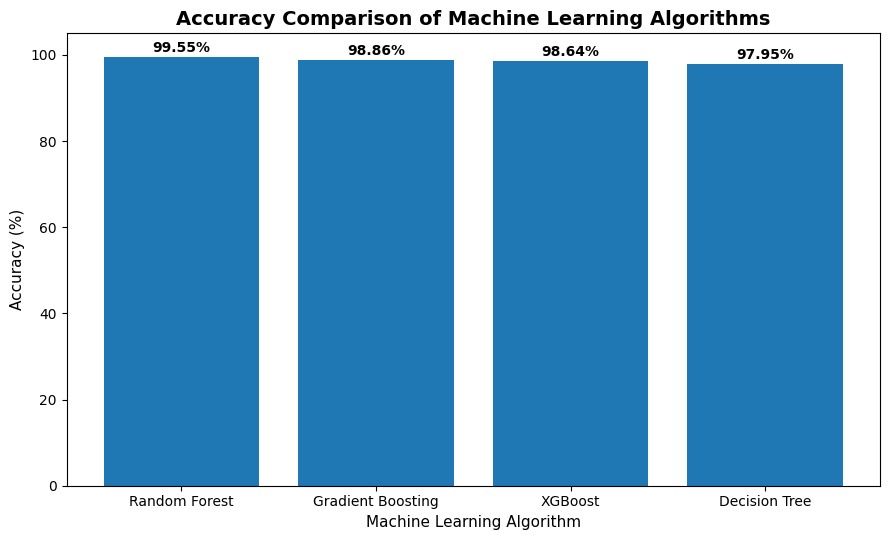

In [ ]:
# ============================================
# FarmSathi - Crop Recommendation
# Accuracy Comparison Graph
# ============================================

import pandas as pd
import matplotlib.pyplot as plt

# Actual accuracies from the trained models
results = {
    "Random Forest": 99.55,
    "Gradient Boosting": 98.86,
    "XGBoost": 98.64,
    "Decision Tree": 97.95
}

# Create DataFrame
results_df = pd.DataFrame(
    list(results.items()),
    columns=["Algorithm", "Accuracy (%)"]
)

# Sort from highest to lowest
results_df = results_df.sort_values(
    "Accuracy (%)",
    ascending=False
)

# Display table
display(results_df)

# Create graph
plt.figure(figsize=(9, 5.5))

bars = plt.bar(
    results_df["Algorithm"],
    results_df["Accuracy (%)"]
)

# Title and labels
plt.title(
    "Accuracy Comparison of Machine Learning Algorithms",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Machine Learning Algorithm",
    fontsize=11
)

plt.ylabel(
    "Accuracy (%)",
    fontsize=11
)

# Y-axis
plt.ylim(0, 105)

# Add accuracy values above bars
for bar, value in zip(
    bars,
    results_df["Accuracy (%)"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.5,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()

# Save high-resolution image
plt.savefig(
    "/content/FarmSathi_Crop_Recommendation_Accuracy_Graph.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()